In [1]:
# import and path

from pathlib import Path
import sys

import numpy as np
import pandas as pd
import tensorflow as tf

from scipy.io import wavfile


# ============================================================
# Repository path
# ============================================================

AI_ROOT = Path(
    "/content/drive/MyDrive/TRON/AI"
)

if str(AI_ROOT) not in sys.path:
    sys.path.insert(0, str(AI_ROOT))

from src.preprocess import (
    preprocess_pcm16,
    NUM_FRAMES,
    NUM_MEL_BINS,
)


# ============================================================
# Dataset paths
# ============================================================

DATASET_ROOT = Path(
    "/content/drive/MyDrive/TRON/AI/dataset"
)

CLIP_ROOT = (
    DATASET_ROOT
    / "processed"
    / "clips_16k_1s"
)

AI05_META = (
    DATASET_ROOT
    / "metadata"
    / "05_split_info"
)

SPLIT_MANIFEST = (
    AI05_META
    / "split_manifest.csv"
)

NORMALIZATION_NPZ = (
    AI05_META
    / "normalization_stats.npz"
)


# ============================================================
# Training configuration
# ============================================================

BATCH_SIZE = 32
SHUFFLE_BUFFER = 5425
RANDOM_SEED = 2026

print("TensorFlow:", tf.__version__)

assert SPLIT_MANIFEST.exists()
assert NORMALIZATION_NPZ.exists()

print("AI-06 path check: OK")

TensorFlow: 2.20.0
AI-06 path check: OK


In [2]:
# load split and mean/std

manifest = pd.read_csv(
    SPLIT_MANIFEST
)

stats = np.load(
    NORMALIZATION_NPZ
)

mean = stats["mean"].astype(
    np.float32
)

std = stats["std"].astype(
    np.float32
)


print("mean shape:", mean.shape)
print("std shape :", std.shape)

assert mean.shape == (40,)
assert std.shape == (40,)

assert np.isfinite(mean).all()
assert np.isfinite(std).all()
assert (std > 0).all()

mean shape: (40,)
std shape : (40,)


In [3]:
# separate splits

train_df = (
    manifest[
        manifest["split"] == "TRAIN"
    ]
    .copy()
    .reset_index(drop=True)
)

val_df = (
    manifest[
        manifest["split"] == "VALIDATION"
    ]
    .copy()
    .reset_index(drop=True)
)

test_df = (
    manifest[
        manifest["split"] == "TEST"
    ]
    .copy()
    .reset_index(drop=True)
)


print("TRAIN     :", len(train_df))
print("VALIDATION:", len(val_df))
print("TEST      :", len(test_df))


assert len(train_df) == 5425
assert len(val_df) == 1162
assert len(test_df) == 1162

TRAIN     : 5425
VALIDATION: 1162
TEST      : 1162


In [4]:
# re-confirm class ID

print(
    train_df[
        ["class_id", "class_name"]
    ]
    .drop_duplicates()
    .sort_values("class_id")
)

    class_id class_name
0        0.0      OTHER
57       1.0      SNORE
48       2.0      COUGH


In [5]:
label_map = (
    train_df[
        ["class_id", "class_name"]
    ]
    .drop_duplicates()
    .sort_values("class_id")
)

expected = {
    0: "OTHER",
    1: "SNORE",
    2: "COUGH",
}

actual = dict(
    zip(
        label_map["class_id"].astype(int),
        label_map["class_name"],
    )
)

assert actual == expected

print(
    "Class mapping check: OK"
)

Class mapping check: OK


In [6]:
# preprocess 1 case

def load_feature(
    relative_path,
):
    """
    AI-03 WAV
        ->
    AI-04 Log-Mel
        ->
    AI-05 mean/std normalization
        ->
    [98, 40, 1] float32
    """

    path = (
        CLIP_ROOT
        / relative_path
    )

    sr, pcm = wavfile.read(
        path
    )

    if sr != 16000:
        raise ValueError(
            f"Invalid sample rate: {sr} "
            f"({path})"
        )

    if pcm.dtype != np.int16:
        raise TypeError(
            f"Invalid dtype: {pcm.dtype} "
            f"({path})"
        )

    if pcm.shape != (16000,):
        raise ValueError(
            f"Invalid PCM shape: "
            f"{pcm.shape} ({path})"
        )

    # AI-04 + AI-05
    feature = preprocess_pcm16(
        pcm,
        mean=mean,
        std=std,
    )

    if feature.shape != (
        NUM_FRAMES,
        NUM_MEL_BINS,
    ):
        raise ValueError(
            f"Invalid feature shape: "
            f"{feature.shape}"
        )

    if not np.isfinite(
        feature
    ).all():
        raise ValueError(
            f"NaN/Inf detected: {path}"
        )

    # CNN channel dimension
    feature = feature[
        :,
        :,
        np.newaxis,
    ]

    return feature.astype(
        np.float32,
        copy=False,
    )

In [7]:
# UT

row = train_df.iloc[0]

feature = load_feature(
    row["relative_path"]
)

label = int(
    row["class_id"]
)

print("Feature shape:", feature.shape)
print("Feature dtype:", feature.dtype)
print("Label        :", label)
print("Class        :", row["class_name"])

print(
    "Feature range:",
    feature.min(),
    feature.max(),
)

assert feature.shape == (
    98,
    40,
    1,
)

assert feature.dtype == np.float32
assert label in (0, 1, 2)

print(
    "Single sample pipeline check: OK"
)

Feature shape: (98, 40, 1)
Feature dtype: float32
Label        : 0
Class        : OTHER
Feature range: 0.46728098 2.1361222
Single sample pipeline check: OK


In [8]:
# python generator

def feature_generator(df):
    """
    Yield:
        feature: float32 [98,40,1]
        label:   int32 scalar
    """

    for _, row in df.iterrows():

        feature = load_feature(
            row["relative_path"]
        )

        label = np.int32(
            row["class_id"]
        )

        yield feature, label

In [9]:
# specify shape and dtype

OUTPUT_SIGNATURE = (
    tf.TensorSpec(
        shape=(
            NUM_FRAMES,
            NUM_MEL_BINS,
            1,
        ),
        dtype=tf.float32,
    ),

    tf.TensorSpec(
        shape=(),
        dtype=tf.int32,
    ),
)

In [10]:
# dataset gen func

def make_dataset(
    df,
    *,
    training,
    batch_size=BATCH_SIZE,
):
    """
    Create tf.data.Dataset.

    Pipeline:
        generator
          -> cache
          -> shuffle (TRAIN only)
          -> batch
          -> prefetch
    """

    ds = tf.data.Dataset.from_generator(
        lambda: feature_generator(df),
        output_signature=OUTPUT_SIGNATURE,
    )

    # 1 epoch目にWAV + preprocessingを実施。
    # 以後はRAM cacheを利用。
    ds = ds.cache()

    if training:
        ds = ds.shuffle(
            buffer_size=len(df),
            seed=RANDOM_SEED,
            reshuffle_each_iteration=True,
        )

    ds = ds.batch(
        batch_size,
        drop_remainder=False,
    )

    ds = ds.prefetch(
        tf.data.AUTOTUNE
    )

    return ds

In [11]:
# train/velidation dataset

train_ds = make_dataset(
    train_df,
    training=True,
)

val_ds = make_dataset(
    val_df,
    training=False,
)

print(
    "TRAIN dataset     :",
    train_ds
)

print(
    "VALIDATION dataset:",
    val_ds
)

TRAIN dataset     : <_PrefetchDataset element_spec=(TensorSpec(shape=(None, 98, 40, 1), dtype=tf.float32, name=None), TensorSpec(shape=(None,), dtype=tf.int32, name=None))>
VALIDATION dataset: <_PrefetchDataset element_spec=(TensorSpec(shape=(None, 98, 40, 1), dtype=tf.float32, name=None), TensorSpec(shape=(None,), dtype=tf.int32, name=None))>


In [12]:
# get only one batch

train_features, train_labels = next(
    iter(train_ds)
)

print(
    "Feature batch shape:",
    train_features.shape
)

print(
    "Feature dtype:",
    train_features.dtype
)

print(
    "Label batch shape:",
    train_labels.shape
)

print(
    "Label dtype:",
    train_labels.dtype
)

print(
    "Labels:",
    train_labels.numpy()
)

Feature batch shape: (32, 98, 40, 1)
Feature dtype: <dtype: 'float32'>
Label batch shape: (32,)
Label dtype: <dtype: 'int32'>
Labels: [2 0 1 1 1 2 2 1 2 0 1 0 0 2 1 0 2 2 2 2 2 1 2 2 2 2 2 1 2 1 0 2]


In [13]:
assert train_features.shape == (
    BATCH_SIZE,
    98,
    40,
    1,
)

assert train_features.dtype == tf.float32

assert train_labels.shape == (
    BATCH_SIZE,
)

assert train_labels.dtype == tf.int32

assert np.isfinite(
    train_features.numpy()
).all()

assert np.isin(
    train_labels.numpy(),
    [0, 1, 2],
).all()

print(
    "TRAIN batch check: OK"
)

TRAIN batch check: OK


In [14]:
# confirm validation

val_features, val_labels = next(
    iter(val_ds)
)

print(
    "VAL feature shape:",
    val_features.shape
)

print(
    "VAL label shape:",
    val_labels.shape
)

assert val_features.shape == (
    BATCH_SIZE,
    98,
    40,
    1,
)

assert val_features.dtype == tf.float32

assert val_labels.dtype == tf.int32

assert np.isfinite(
    val_features.numpy()
).all()

print(
    "VALIDATION batch check: OK"
)

VAL feature shape: (32, 98, 40, 1)
VAL label shape: (32,)
VALIDATION batch check: OK


In [15]:
# confirm batch nums

import math

expected_train_batches = math.ceil(
    len(train_df)
    / BATCH_SIZE
)

expected_val_batches = math.ceil(
    len(val_df)
    / BATCH_SIZE
)

print(
    "Expected TRAIN batches:",
    expected_train_batches
)

print(
    "Expected VAL batches:",
    expected_val_batches
)

Expected TRAIN batches: 170
Expected VAL batches: 37


In [16]:
print(
    "TRAIN cardinality:",
    tf.data.experimental.cardinality(
        train_ds
    ).numpy()
)

print(
    "VAL cardinality:",
    tf.data.experimental.cardinality(
        val_ds
    ).numpy()
)

TRAIN cardinality: -2
VAL cardinality: -2


In [17]:
# confirm class dist.

print(
    "=== TRAIN class distribution ==="
)

print(
    train_df["class_name"]
    .value_counts()
)

print()
print(
    "=== VALIDATION class distribution ==="
)

print(
    val_df["class_name"]
    .value_counts()
)

=== TRAIN class distribution ===
class_name
COUGH    3586
OTHER    1064
SNORE     775
Name: count, dtype: int64

=== VALIDATION class distribution ===
class_name
COUGH    768
OTHER    228
SNORE    166
Name: count, dtype: int64


#### baseline CNN定義

In [18]:
# class weight 算出

from sklearn.utils.class_weight import compute_class_weight

classes = np.array([0, 1, 2], dtype=np.int32)

class_weights_array = compute_class_weight(
    class_weight="balanced",
    classes=classes,
    y=train_df["class_id"].astype(int).to_numpy(),
)

class_weight = {
    int(cls): float(weight)
    for cls, weight in zip(
        classes,
        class_weights_array,
    )
}

print(class_weight)

{0: 1.6995614035087718, 1: 2.3333333333333335, 2: 0.5042758877114706}


In [19]:
# baseline CNN

from tensorflow import keras
from tensorflow.keras import layers

model = keras.Sequential([
    layers.Input(
        shape=(98, 40, 1)
    ),

    layers.Conv2D(
        8,
        kernel_size=(3, 3),
        padding="same",
        use_bias=False,
    ),
    layers.BatchNormalization(),
    layers.ReLU(),
    layers.MaxPooling2D(
        pool_size=(2, 2)
    ),

    layers.Conv2D(
        16,
        kernel_size=(3, 3),
        padding="same",
        use_bias=False,
    ),
    layers.BatchNormalization(),
    layers.ReLU(),
    layers.MaxPooling2D(
        pool_size=(2, 2)
    ),

    layers.Conv2D(
        32,
        kernel_size=(3, 3),
        padding="same",
        use_bias=False,
    ),
    layers.BatchNormalization(),
    layers.ReLU(),

    layers.GlobalAveragePooling2D(),

    layers.Dense(
        3,
        activation="softmax",
    ),
])

model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 98, 40, 8)      │            72 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 98, 40, 8)      │            32 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ re_lu (ReLU)                    │ (None, 98, 40, 8)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 49, 20, 8)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 49, 20, 16)     │         1,152 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 49, 20, 16)     │            64 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ re_lu_1 (ReLU)                  │ (None, 49, 20, 16)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 24, 10, 16)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 24, 10, 32)     │         4,608 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 24, 10, 32)     │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ re_lu_2 (ReLU)                  │ (None, 24, 10, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 32)             │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 3)              │            99 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 6,155 (24.04 KB)

 Trainable params: 6,043 (23.61 KB)

 Non-trainable params: 112 (448.00 B)

In [20]:
# compile

model.compile(
    optimizer=keras.optimizers.Adam(
        learning_rate=1e-3
    ),
    loss=keras.losses.SparseCategoricalCrossentropy(),
    metrics=[
        keras.metrics.SparseCategoricalAccuracy(
            name="accuracy"
        )
    ],
)

In [21]:
# confirm param nums

total_params = model.count_params()

print(
    "Total parameters:",
    total_params
)

print(
    "Approx float32 parameter size:",
    total_params * 4 / 1024,
    "KiB"
)

Total parameters: 6155
Approx float32 parameter size: 24.04296875 KiB


In [22]:
# callbacks

from pathlib import Path
from tensorflow import keras

MODEL_DIR = AI_ROOT / "model"
MODEL_DIR.mkdir(
    parents=True,
    exist_ok=True,
)

BEST_MODEL_PATH = (
    MODEL_DIR
    / "baseline_float32.keras"
)

callbacks = [
    keras.callbacks.ModelCheckpoint(
        filepath=BEST_MODEL_PATH,
        monitor="val_loss",
        mode="min",
        save_best_only=True,
        verbose=1,
    ),

    keras.callbacks.EarlyStopping(
        monitor="val_loss",
        mode="min",
        patience=8,
        restore_best_weights=True,
        verbose=1,
    ),

    keras.callbacks.ReduceLROnPlateau(
        monitor="val_loss",
        mode="min",
        factor=0.5,
        patience=3,
        min_lr=1e-6,
        verbose=1,
    ),
]

In [ ]:
history = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=50,
    class_weight=class_weight,
    callbacks=callbacks,
    verbose=1,
)

Epoch 1/50
    170/Unknown 21s 122ms/step - accuracy: 0.8439 - loss: 0.5460
Epoch 1: val_loss improved from None to 0.79179, saving model to /content/drive/MyDrive/TRON/AI/model/baseline_float32.keras

Epoch 1: finished saving model to /content/drive/MyDrive/TRON/AI/model/baseline_float32.keras
170/170 ━━━━━━━━━━━━━━━━━━━━ 313s 2s/step - accuracy: 0.8590 - loss: 0.5195 - val_accuracy: 0.6446 - val_loss: 0.7918 - learning_rate: 0.0010
Epoch 2/50
169/170 ━━━━━━━━━━━━━━━━━━━━ 0s 102ms/step - accuracy: 0.8709 - loss: 0.4746
Epoch 2: val_loss did not improve from 0.79179
170/170 ━━━━━━━━━━━━━━━━━━━━ 18s 107ms/step - accuracy: 0.8798 - loss: 0.4521 - val_accuracy: 0.5775 - val_loss: 1.0781 - learning_rate: 0.0010
Epoch 3/50
170/170 ━━━━━━━━━━━━━━━━━━━━ 0s 95ms/step - accuracy: 0.8876 - loss: 0.4223
Epoch 3: val_loss improved from 0.79179 to 0.31898, saving model to /content/drive/MyDrive/TRON/AI/model/baseline_float32.keras

Epoch 3: finished saving model to /content/drive/MyDrive/TRON/AI/mo

In [25]:
print(
    "Best validation loss:",
    min(history.history["val_loss"])
)

print(
    "Best validation accuracy:",
    max(history.history["val_accuracy"])
)

Best validation loss: 0.1715073436498642
Best validation accuracy: 0.9406196475028992


In [26]:
history_df = pd.DataFrame(
    history.history
)

history_df

,accuracy,loss,val_accuracy,val_loss,learning_rate
0,0.858986,0.519535,0.644578,0.791791,0.001000
1,0.879816,0.452102,0.577453,1.078131,0.001000
2,0.892903,0.405602,0.871773,0.318984,0.001000
3,0.910046,0.357516,0.761618,0.593925,0.001000
4,0.918894,0.332473,0.763339,0.586620,0.001000
5,0.921659,0.310938,0.892427,0.312154,0.001000
6,0.920184,0.303951,0.778830,0.573842,0.001000
7,0.927005,0.279451,0.913081,0.239535,0.001000
8,0.928848,0.269695,0.920826,0.243426,0.001000
9,0.931982,0.263321,0.890706,0.314721,0.001000


In [27]:
TRAINING_META = (
    DATASET_ROOT
    / "metadata"
    / "06_training_info"
)

TRAINING_META.mkdir(
    parents=True,
    exist_ok=True,
)

HISTORY_CSV = (
    TRAINING_META
    / "training_history.csv"
)

history_df.to_csv(
    HISTORY_CSV,
    index=False,
)

print("Saved:", HISTORY_CSV)

Saved: /content/drive/MyDrive/TRON/AI/dataset/metadata/06_training_info/training_history.csv


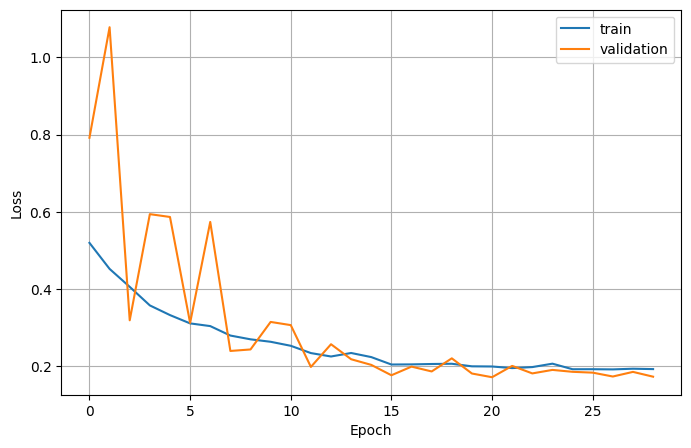

In [28]:
import matplotlib.pyplot as plt

history_df = pd.DataFrame(history.history)

plt.figure(figsize=(8, 5))
plt.plot(history_df["loss"], label="train")
plt.plot(history_df["val_loss"], label="validation")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()
plt.grid()
plt.show()

In [29]:
best_model = tf.keras.models.load_model(
    BEST_MODEL_PATH
)

val_loss, val_accuracy = best_model.evaluate(
    val_ds,
    verbose=1,
)

print("Reloaded best model")
print("val_loss    :", val_loss)
print("val_accuracy:", val_accuracy)

37/37 ━━━━━━━━━━━━━━━━━━━━ 3s 59ms/step - accuracy: 0.9346 - loss: 0.1715
Reloaded best model
val_loss    : 0.1715073436498642
val_accuracy: 0.93459552526474


/usr/local/lib/python3.13/dist-packages/keras/src/trainers/epoch_iterator.py:164: UserWarning: Your input ran out of data; interrupting training. Make sure that your dataset or generator can generate at least `steps_per_epoch * epochs` batches. You may need to use the `.repeat()` function when building your dataset.
  self._interrupted_warning()
